<a href="https://colab.research.google.com/github/winireis/IA-AM-Predicao-da-Qualidade-Sensorial-de-Vinhos/blob/main/IA_AM_Predi%C3%A7%C3%A3o_da_Qualidade_Sensorial_de_Vinhos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Redes Neurais na Predição da Qualidade Sensorial de Vinhos
- Aline Franciele Camillo
- Davi Cardoso Lobo
- Josias Dias de Andrade
- Winicius Reis de Jesus Ferreira

# Introdução
A avaliação da qualidade de um vinho depende tradicionalmente de sommeliers; um processo subjetivo, não escalável e custoso. Mas, e se pudessemos utilizar variáveis físico-químicas mensuráveis em laboratório e prever a avaliação sensorial que um sommelier daria para um vinho?

O objetivo desse trabalho é aplicar técnicas de análise de dados, aprendizado de máquina e inteligência artificial na base de dados Wine Quality Dataset para identificar a qualidade de um vinho de forma eficiente.

Foram treinadas três redes com as seguintes configurações: uma camada intermediária de 32 neurônios, uma camada intermediária de 64 e mais outra de 32, uma camada intermediária de 128 e mais outra de 64 neurônios.

# Desenvolvimento
A base de dados Wine Quality Dataset contém 12 atributos, sendo 11 atributos físico-químicos e 1 atributo sensorial.
- Físico-Químicos: Acidez fixa, acidez volátil, ácido cítrico, açúcar residual, cloretos, dióxido de enxofre livre/total, densidade, pH, sulfatos, álcool.
- Sensorial: Qualidade em uma escala de 0 a 10.

Na etapa de pré-processamento fizemos a normalização dos atributos físico-químicos, agrupamento do atributo sensorial em 3 classes(Ruim, Bom e Ótimo), e separação dos dados em 60% para treino, 20% para validação e 20% para teste.

# Resultados Preliminares
O desempenho das redes neurais na predição da qualidade sensorial de vinhos apresentou resultados aquém dos esperados. Um dos fatores é a inerente baixa quantidade de amostras nas qualidades mais baixas e nas qualidade mais altas dos vinhos.

Uma futura comparação de desempenho utilizando algoritmos de Regressão Logística, Regressão Linerar, Naïve Bayes e K-Vizinhos se mostra interessante; dada a natureza classificação de qualidade dos vinhos em notas de 0 a 10.

# Referências
1. CORTEZ, Paulo et al. Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, Elsevier, v. 47, n. 4, p. 547-553, 2009.
2. UCI Machine Learning Repository: Wine Quality Data Set. Disponível em: https://archive.ics.uci.edu/ml/datasets/wine+quality

In [ ]:
# 0. Instalação de bibliotecas externas
# Biblioteca de acesso ao repositório de dados da UCI
!pip install ucimlrepo

In [ ]:
# 0. Importação dos recursos utilizados no experimento
from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE

In [ ]:
# 1. Aquisição dos dados do experimento
# Dataset - Wine Quality
wine_quality = fetch_ucirepo(id=186)
# Dataframes em Pandas
X = wine_quality.data.features
y = wine_quality.data.targets

In [ ]:
# 2.1 Exploração dos Dados - X
print("--- ANÁLISE DE X ---")
print("Atributos do X:")
print(X.columns.tolist())
print("\nInformações Gerais:")
X.info()
print("\nResumo Estatístico:")
display(X.describe())

--- ANÁLISE DE X ---
Atributos do X:
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Informações Gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000


In [ ]:
# 2.2 Exploração dos Dados - Y
print("--- ANÁLISE DE Y ---")
print("Atributos do Y:")
print(y.columns.tolist())
print("\nClasses de Y:")
print(y.value_counts().sort_index())
print("\nInformações Gerais:")
y.info()
print("\nResumo Estatístico:")
display(y.describe())

--- ANÁLISE DE Y ---
Atributos do Y:
['quality']

Classes de Y:
quality
3            30
4           216
5          2138
6          2836
7          1079
8           193
9             5
Name: count, dtype: int64

Informações Gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   quality  6497 non-null   int64
dtypes: int64(1)
memory usage: 50.9 KB

Resumo Estatístico:


,quality
count,6497.000000
mean,5.818378
std,0.873255
min,3.000000
25%,5.000000
50%,6.000000
75%,6.000000
max,9.000000


In [ ]:
# 2.3 Tratamento de classes de Y
# Y pode assumir o valor de 1~10; porém tem classes majoritárias e nem todas as classes parecem na base de dados
# Realizaremos o agrupamento de classes:
# 1 a 5 -> Classe 1 (Ruim)
# 6 a 7 -> Classe 2 (Bom)
# 8 a 10 -> Classe 3 (Ótimo)

bins = [0, 5, 7, 10]
labels = [1, 2, 3]

y = pd.cut(y['quality'], bins=bins, labels=labels)
print("\nClasses de Y:")
print(y.value_counts().sort_index())



Classes de Y:
quality
1    2384
2    3915
3     198
Name: count, dtype: int64


In [ ]:
# 3. Separação de 60% para Treino, 20% para Validação e 20% para Teste
# Primeiro passo: separa 60% para Treino e 40% temporário (Validação + Teste)
# A estratificação garante a mesma proporção de classes
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

# Segundo passo: divide os 40% restantes igualmente entre Validação (20%) e Teste (20%)
# A estratificação garante a mesma proporção de classes
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print(f"Tamanho do Treino: {len(X_train)} linhas ({len(X_train)/len(X)*100:.0f}%)")
print(f"Tamanho da Validação: {len(X_val)} linhas ({len(X_val)/len(X)*100:.0f}%)")
print(f"Tamanho do Teste: {len(X_test)} linhas ({len(X_test)/len(X)*100:.0f}%)")

Tamanho do Treino: 3898 linhas (60%)
Tamanho da Validação: 1299 linhas (20%)
Tamanho do Teste: 1300 linhas (20%)


In [ ]:
# 4.1 Normalização dos Dados
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 4.2 Oversampling de classes minoritárias
# Seleção simples se deseja utilizar os dados com ou sem oversampling
oversampling = False
if oversampling:
  # Aplicando o SMOTE apenas nos dados de treino
  smote = SMOTE(random_state=42)
  X_train, y_train = smote.fit_resample(X_train, y_train)


In [ ]:
# 5.1 Treinamento da Rede Neural - Modo Básico
mlp_low = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

mlp_low.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=42)

In [ ]:
# 5.2 Treinamento da Rede Neural - Modo Intermediário
mlp_medium = MLPClassifier(
    hidden_layer_sizes=(64,32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

mlp_medium.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)

In [ ]:
# 5.3 Treinamento da Rede Neural - Modo Avançado
mlp_high = MLPClassifier(
    hidden_layer_sizes=(128,64),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

mlp_high.fit(X_train, y_train)

MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, random_state=42)

In [ ]:
# 6.1 Avaliação com conjunto de Validação - Básico
y_val_pred = mlp_low.predict(X_val_scaled)
print("--- Modelo de Rede Neural Básico ---")
print(f"Acurácia na Validação: {accuracy_score(y_val, y_val_pred):.4f}\n")
print("Relatório de Classificação (Validação):")
print(classification_report(y_val, y_val_pred, zero_division=0))

--- Modelo de Rede Neural Básico ---
Acurácia na Validação: 0.7367

Relatório de Classificação (Validação):
              precision    recall  f1-score   support

           1       0.70      0.63      0.66       477
           2       0.75      0.84      0.79       783
           3       0.33      0.03      0.05        39

    accuracy                           0.74      1299
   macro avg       0.60      0.50      0.50      1299
weighted avg       0.72      0.74      0.72      1299



In [ ]:
# 6.1 Avaliação com conjunto de Validação - Intermediário
y_val_pred = mlp_medium.predict(X_val_scaled)
print("--- Modelo de Rede Neural Intermediário ---")
print(f"Acurácia na Validação: {accuracy_score(y_val, y_val_pred):.4f}\n")
print("Relatório de Classificação (Validação):")
print(classification_report(y_val, y_val_pred, zero_division=0))

--- Modelo de Rede Neural Intermediário ---
Acurácia na Validação: 0.7521

Relatório de Classificação (Validação):
              precision    recall  f1-score   support

           1       0.73      0.64      0.68       477
           2       0.77      0.85      0.81       783
           3       0.50      0.18      0.26        39

    accuracy                           0.75      1299
   macro avg       0.67      0.56      0.58      1299
weighted avg       0.75      0.75      0.74      1299



In [ ]:
# 6.1 Avaliação com conjunto de Validação - Avançado
y_val_pred = mlp_high.predict(X_val_scaled)
print("--- Modelo de Rede Neural Avançado ---")
print(f"Acurácia na Validação: {accuracy_score(y_val, y_val_pred):.4f}\n")
print("Relatório de Classificação (Validação):")
print(classification_report(y_val, y_val_pred, zero_division=0))

--- Modelo de Rede Neural Avançado ---
Acurácia na Validação: 0.7513

Relatório de Classificação (Validação):
              precision    recall  f1-score   support

           1       0.72      0.69      0.70       477
           2       0.78      0.81      0.80       783
           3       0.33      0.26      0.29        39

    accuracy                           0.75      1299
   macro avg       0.61      0.59      0.60      1299
weighted avg       0.75      0.75      0.75      1299



In [ ]:
# 7.1 Avaliação com conjunto de Teste
y_test_pred = mlp_medium.predict(X_test_scaled)
print(f"Acurácia no Teste: {accuracy_score(y_test, y_test_pred):.4f}")
print("Relatório de Classificação (Teste):")
print(classification_report(y_test, y_test_pred, zero_division=0))

Acurácia no Teste: 0.7215
Relatório de Classificação (Teste):
              precision    recall  f1-score   support

           1       0.67      0.65      0.66       477
           2       0.76      0.79      0.77       783
           3       0.53      0.25      0.34        40

    accuracy                           0.72      1300
   macro avg       0.65      0.56      0.59      1300
weighted avg       0.72      0.72      0.72      1300



<Figure size 1000x600 with 0 Axes>

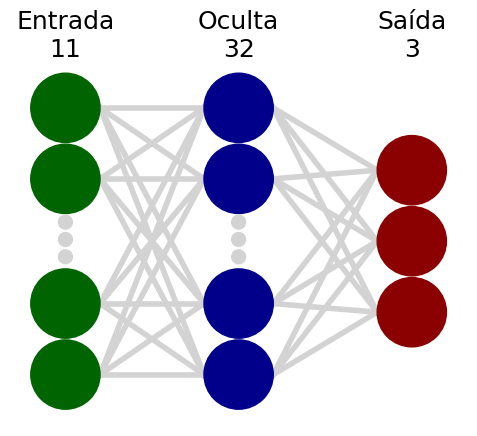

In [ ]:
#Extra Criação de Imagens
!pip install nnv
from nnv import NNV
import matplotlib.pyplot as plt

layersList = [
    {
        "title": "Entrada\n11",
        "units": 11,
        "color": "darkGreen"
    },
    {
        "title": "Oculta\n32",
        "units": 32,
        "max_number_of_nodes_to_show": 8, # Exibe uma quantidade limpa com reticências para representar os 32
        "color": "darkBlue"
    },
    {
        "title": "Saída\n3",
        "units": 3,
        "color": "darkRed"
    }
]

# Gerando e salvando a imagem em alta resolução para o banner
plt.figure(figsize=(10, 6))
NNV(layersList).render(save_to_file="rede_1.png")
plt.show()

<Figure size 3600x1800 with 0 Axes>

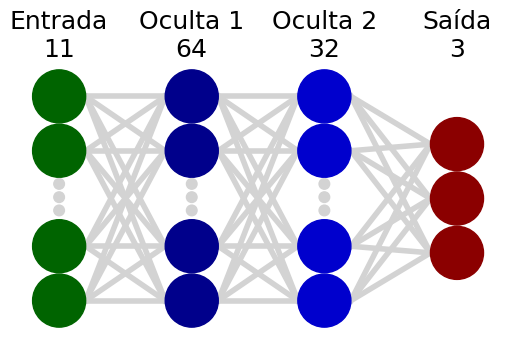

In [ ]:
#Extra Criação de Imagens
layersList = [
    {
        "title": "Entrada\n11",
        "units": 11,
        "color": "darkGreen"
    },
    {
        "title": "Oculta 1\n64",
        "units": 64,
        "max_number_of_nodes_to_show": 8, # Resumo visual para não lotar a imagem
        "color": "darkBlue"
    },
    {
        "title": "Oculta 2\n32",
        "units": 32,
        "max_number_of_nodes_to_show": 8, # Resumo visual
        "color": "mediumBlue"
    },
    {
        "title": "Saída\n3",
        "units": 3,
        "color": "darkRed"
    }
]

# 4. Gerando e salvando a imagem em alta resolução (ideal para o banner)
plt.figure(figsize=(12, 6), dpi=300)
NNV(layersList).render(save_to_file="rede_2.png")
plt.show()

<Figure size 3600x1800 with 0 Axes>

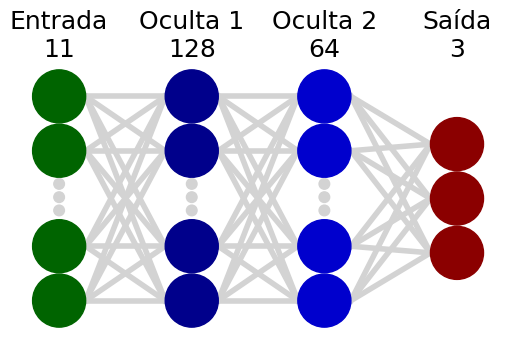

In [ ]:
#Extra Criação de Imagens
layersList = [
    {
        "title": "Entrada\n11",
        "units": 11,
        "color": "darkGreen"
    },
    {
        "title": "Oculta 1\n128",
        "units": 128,
        "max_number_of_nodes_to_show": 8, # Resumo visual para não lotar a imagem
        "color": "darkBlue"
    },
    {
        "title": "Oculta 2\n64",
        "units": 64,
        "max_number_of_nodes_to_show": 8, # Resumo visual
        "color": "mediumBlue"
    },
    {
        "title": "Saída\n3",
        "units": 3,
        "color": "darkRed"
    }
]

# 4. Gerando e salvando a imagem em alta resolução (ideal para o banner)
plt.figure(figsize=(12, 6), dpi=300)
NNV(layersList).render(save_to_file="rede_3.png")
plt.show()